In [20]:
import pandas as pd
import numpy as np

file_path = "../data/processed/cicids2017_combined.csv"
chunk_size = 50000

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

columns = pd.read_csv(file_path, nrows=0).columns.tolist()
feature_cols = [col for col in columns if col not in ["Label", "source_file"]]

print("Number of columns:", len(columns))
print("Columns:", columns)

Number of columns: 80
Columns: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'C

In [21]:
first_chunk = pd.read_csv(file_path, nrows=chunk_size)
print(first_chunk.dtypes.to_string())

Destination Port                 int64
Flow Duration                    int64
Total Fwd Packets                int64
Total Backward Packets           int64
Total Length of Fwd Packets      int64
Total Length of Bwd Packets      int64
Fwd Packet Length Max            int64
Fwd Packet Length Min            int64
Fwd Packet Length Mean         float64
Fwd Packet Length Std          float64
Bwd Packet Length Max            int64
Bwd Packet Length Min            int64
Bwd Packet Length Mean         float64
Bwd Packet Length Std          float64
Flow Bytes/s                   float64
Flow Packets/s                 float64
Flow IAT Mean                  float64
Flow IAT Std                   float64
Flow IAT Max                     int64
Flow IAT Min                     int64
Fwd IAT Total                    int64
Fwd IAT Mean                   float64
Fwd IAT Std                    float64
Fwd IAT Max                      int64
Fwd IAT Min                      int64
Bwd IAT Total            

In [22]:
# missing values
missing = pd.Series(0, index=columns)
total_rows = 0

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    total_rows += len(chunk)
    missing += chunk.isna().sum()

missing_report = pd.DataFrame({
    "Missing": missing,
    "Percent": missing / total_rows * 100
})

print("Total rows:", total_rows)
print(missing_report.to_string())

Total rows: 2830743
                             Missing   Percent
Destination Port                   0  0.000000
Flow Duration                      0  0.000000
Total Fwd Packets                  0  0.000000
Total Backward Packets             0  0.000000
Total Length of Fwd Packets        0  0.000000
Total Length of Bwd Packets        0  0.000000
Fwd Packet Length Max              0  0.000000
Fwd Packet Length Min              0  0.000000
Fwd Packet Length Mean             0  0.000000
Fwd Packet Length Std              0  0.000000
Bwd Packet Length Max              0  0.000000
Bwd Packet Length Min              0  0.000000
Bwd Packet Length Mean             0  0.000000
Bwd Packet Length Std              0  0.000000
Flow Bytes/s                    1358  0.047973
Flow Packets/s                     0  0.000000
Flow IAT Mean                      0  0.000000
Flow IAT Std                       0  0.000000
Flow IAT Max                       0  0.000000
Flow IAT Min                       0  0.

In [23]:
# infinite values
infinite = pd.Series(0, index=feature_cols)
non_numeric = pd.Series(0, index=feature_cols)

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    for col in feature_cols:
        values = pd.to_numeric(chunk[col], errors="coerce")
        infinite[col] += np.isinf(values).sum()
        non_numeric[col] += (chunk[col].notna() & values.isna()).sum()

quality_report = pd.DataFrame({
    "Infinite": infinite,
    "Non-numeric values": non_numeric
})
print(quality_report.to_string())

                             Infinite  Non-numeric values
Destination Port                    0                   0
Flow Duration                       0                   0
Total Fwd Packets                   0                   0
Total Backward Packets              0                   0
Total Length of Fwd Packets         0                   0
Total Length of Bwd Packets         0                   0
Fwd Packet Length Max               0                   0
Fwd Packet Length Min               0                   0
Fwd Packet Length Mean              0                   0
Fwd Packet Length Std               0                   0
Bwd Packet Length Max               0                   0
Bwd Packet Length Min               0                   0
Bwd Packet Length Mean              0                   0
Bwd Packet Length Std               0                   0
Flow Bytes/s                     1509                   0
Flow Packets/s                   2867                   0
Flow IAT Mean 

In [24]:
# min/max values
minimum = pd.Series(np.inf, index=feature_cols)
maximum = pd.Series(-np.inf, index=feature_cols)

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    for col in feature_cols:
        values = pd.to_numeric(chunk[col], errors="coerce")
        values = values[np.isfinite(values)]
        if len(values) > 0:
            minimum[col] = min(minimum[col], values.min())
            maximum[col] = max(maximum[col], values.max())

range_report = pd.DataFrame({"Min": minimum, "Max": maximum})
print(range_report.to_string())

constant = range_report[(range_report["Min"] == range_report["Max"]) & np.isfinite(range_report["Min"])]
print("\nConstant features:")
print(constant.to_string())

                                      Min           Max
Destination Port             0.000000e+00  6.553500e+04
Flow Duration               -1.300000e+01  1.200000e+08
Total Fwd Packets            1.000000e+00  2.197590e+05
Total Backward Packets       0.000000e+00  2.919220e+05
Total Length of Fwd Packets  0.000000e+00  1.290000e+07
Total Length of Bwd Packets  0.000000e+00  6.554530e+08
Fwd Packet Length Max        0.000000e+00  2.482000e+04
Fwd Packet Length Min        0.000000e+00  2.325000e+03
Fwd Packet Length Mean       0.000000e+00  5.940857e+03
Fwd Packet Length Std        0.000000e+00  7.125597e+03
Bwd Packet Length Max        0.000000e+00  1.953000e+04
Bwd Packet Length Min        0.000000e+00  2.896000e+03
Bwd Packet Length Mean       0.000000e+00  5.800500e+03
Bwd Packet Length Std        0.000000e+00  8.194660e+03
Flow Bytes/s                -2.610000e+08  2.071000e+09
Flow Packets/s              -2.000000e+06  4.000000e+06
Flow IAT Mean               -1.300000e+01  1.200

In [25]:
# distribution of normal and different attack labels
label_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(file_path, chunksize=chunk_size):
    labels = chunk["Label"].astype("string").str.strip().fillna("<MISSING>")
    counts = labels.value_counts()
    label_counts = label_counts.add(counts, fill_value=0)

label_report = pd.DataFrame({
    "Count": label_counts.astype(int),
    "Percent": label_counts / total_rows * 100
}).sort_values("Count", ascending=False)

print(label_report.to_string())

                              Count    Percent
Label                                         
BENIGN                      2273097  80.300366
DoS Hulk                     231073   8.162981
PortScan                     158930   5.614427
DDoS                         128027   4.522735
DoS GoldenEye                 10293   0.363615
FTP-Patator                    7938   0.280421
SSH-Patator                    5897    0.20832
DoS slowloris                  5796   0.204752
DoS Slowhttptest               5499    0.19426
Bot                            1966   0.069452
Web Attack � Brute Force       1507   0.053237
Web Attack � XSS                652   0.023033
Infiltration                     36   0.001272
Web Attack � Sql Injection       21   0.000742
Heartbleed                       11   0.000389


In [26]:
# comparison of Fwd Header Length and Fwd Header Length.1
col1 = "Fwd Header Length"
col2 = "Fwd Header Length.1"

if col1 in columns and col2 in columns:
    different = 0
    for chunk in pd.read_csv(file_path, chunksize=chunk_size, usecols=[col1, col2]):
        same = chunk[col1].eq(chunk[col2]) | (chunk[col1].isna() & chunk[col2].isna())
        different += (~same).sum()
    print("Rows where the columns differ:", different)
else:
    print("Both header-length columns were not found.")

Rows where the columns differ: 0


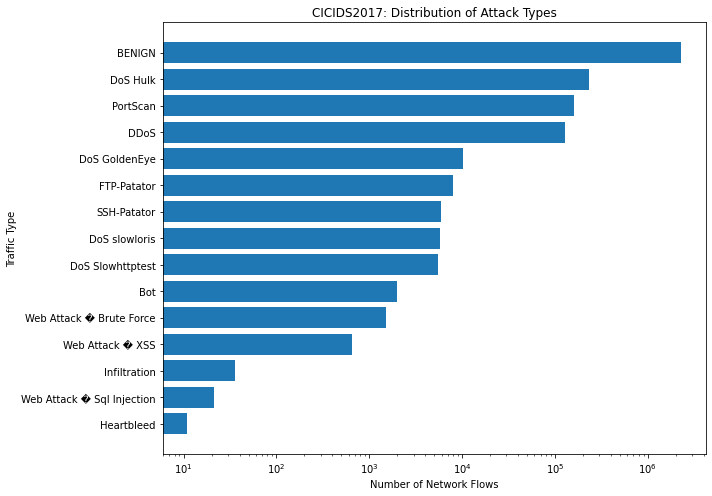

In [29]:
import matplotlib.pyplot as plt

sorted_labels = label_counts.sort_values()

plt.figure(figsize=(10, 7))

plt.barh(sorted_labels.index, sorted_labels.values)

plt.title("CICIDS2017: Distribution of Attack Types")
plt.xlabel("Number of Network Flows")
plt.ylabel("Traffic Type")

plt.xscale("log")
plt.tight_layout()
plt.savefig("attack_type_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()